# Paper 24: Learning Transferable Visual Models From Natural Language Supervision (CLIP)
**Authors**: Alec Radford, Jong Wook Kim, Chris Hallacy, Aditya Ramesh, Gabriel Goh, Sandhini Agarwal, Girish Sastry, Amanda Askell, Pamela Mishkin, Jack Clark, Gretchen Krueger, Ilya Sutskever (OpenAI, ICML 2021)

---

## 1. The Historical Breaking Point: The Fixed-Class Label Straitjacket
Standard vision models were pre-trained to predict a 1-of-1,000 discrete integer index on ImageNet. This made models rigid, incapable of open-vocabulary understanding, and impossible to transfer to new tasks without manual annotation and training a new linear head.

## 2. The Thought Experiment: Open-Vocabulary Cross-Modal Contrastive Learning
CLIP pairs images with raw natural language captions. Within an $N \times N$ batch of candidate pairings:
- The $N$ diagonal entries $(I_i, T_i)$ represent positive matches.
- The $N^2 - N$ off-diagonal entries represent negative distractor pairings.

$$\mathcal{L} = \frac{1}{2} \left( \text{CrossEntropy}(S, \text{labels}) + \text{CrossEntropy}(S^T, \text{labels}) \right)$$
where $S = (I_e \cdot T_e^T) \cdot \exp(\tau)$.

In this notebook, you will explore:
1. Multimodal feature extraction and $L_2$ normalization
2. Symmetric cross-modal similarity matrices
3. Zero-shot visual classification with natural language prompts

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from model import (
    VisionBackbone,
    TextTransformerEncoder,
    CLIP,
)

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.14.1+cpu


---
## 1. Cross-Modal Similarity Matrix Dynamics
In CLIP, both image embeddings $I_e$ and text embeddings $T_e$ are normalized to the unit hypersphere. The similarity matrix $S = (I_e \cdot T_e^T) \cdot \exp(\tau)$ produces pairwise cosine affinities.

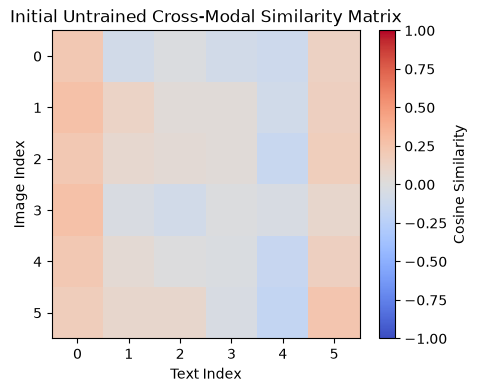

In [2]:
torch.manual_seed(42)
N = 6
embed_dim = 32
clip = CLIP(embed_dim=embed_dim, image_dim=32, text_dim=32, vocab_size=100)

imgs = torch.randn(N, 3, 16, 16)
texts = torch.randint(0, 100, (N, 8))

with torch.no_grad():
    loss, l_i, l_t = clip(imgs, texts)
    sim_matrix = (clip.encode_image(imgs) @ clip.encode_text(texts).T).cpu().numpy()

plt.figure(figsize=(5, 4))
plt.imshow(sim_matrix, cmap="coolwarm", vmin=-1.0, vmax=1.0)
plt.colorbar(label="Cosine Similarity")
plt.title("Initial Untrained Cross-Modal Similarity Matrix")
plt.xlabel("Text Index")
plt.ylabel("Image Index")
plt.show()

---
## 2. Multimodal Contrastive Training Loop
Let's train CLIP on 4 distinct multimodal image-text concepts and observe the rapid alignment of the joint embedding space.

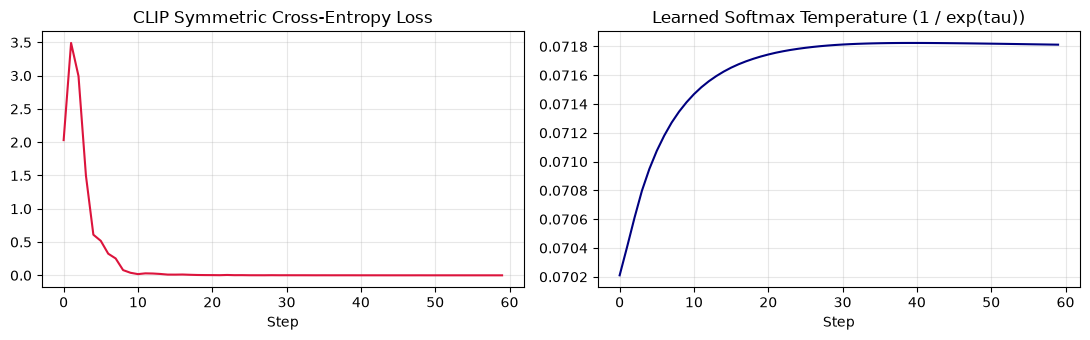

In [3]:
torch.manual_seed(42)
B = 4
clip = CLIP(embed_dim=32, image_dim=32, text_dim=32, vocab_size=100)
optimizer = torch.optim.AdamW(clip.parameters(), lr=3e-3, weight_decay=1e-4)

toy_imgs = torch.randn(B, 3, 16, 16)
toy_texts = torch.tensor([
    [5, 10, 15, 20],
    [25, 30, 35, 40],
    [50, 55, 60, 65],
    [75, 80, 85, 90],
], dtype=torch.long)

losses = []
temp_values = []

for step in range(60):
    optimizer.zero_grad()
    loss, l_i, l_t = clip(toy_imgs, toy_texts)
    loss.backward()
    optimizer.step()

    losses.append(loss.item())
    temp_values.append(1.0 / clip.logit_scale.exp().item())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(losses, color="crimson")
axes[0].set_title("CLIP Symmetric Cross-Entropy Loss")
axes[0].set_xlabel("Step")
axes[0].grid(True, alpha=0.3)

axes[1].plot(temp_values, color="navy")
axes[1].set_title("Learned Softmax Temperature (1 / exp(tau))")
axes[1].set_xlabel("Step")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3. Zero-Shot Visual Classification via Text Prompts
We can query our trained multimodal model using text prompts without any linear probes or classification layers!

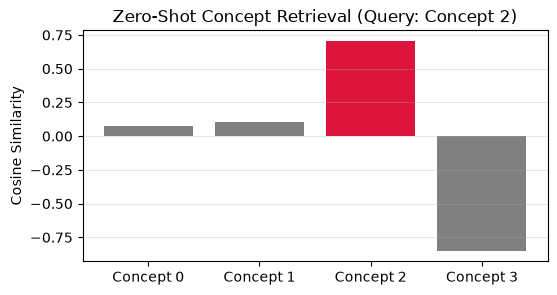

Correctly retrieved Concept 2: True (Index 2)


In [4]:
clip.eval()
with torch.no_grad():
    # Compute normalized text classifier weights for all 4 candidate concepts
    text_weights = clip.encode_text(toy_texts)  # (4, embed_dim)

    # Query with test image 2
    query_img = toy_imgs[2:3]
    query_embed = clip.encode_image(query_img)  # (1, embed_dim)

    # Cosine similarities
    sims = (query_embed @ text_weights.T)[0].cpu().numpy()

plt.figure(figsize=(6, 3))
plt.bar([f"Concept {i}" for i in range(4)], sims, color=["gray", "gray", "crimson", "gray"])
plt.ylabel("Cosine Similarity")
plt.title("Zero-Shot Concept Retrieval (Query: Concept 2)")
plt.grid(True, alpha=0.3, axis="y")
plt.show()

predicted_concept = sims.argmax()
print(f"Correctly retrieved Concept 2: {predicted_concept == 2} (Index {predicted_concept})")